In [1]:
!pip3 install -U ucimlrepo

In [48]:
from ucimlrepo import fetch_ucirepo, list_available_datasets
list_available_datasets()
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from datetime import timedelta
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    classification_report, accuracy_score, precision_score,
    recall_score, f1_score, roc_auc_score, confusion_matrix
)

-------------------------------------
The following datasets are available:
-------------------------------------
Dataset Name                                                                            ID    
------------                                                                            --    
Abalone                                                                                 1     
Adult                                                                                   2     
Annealing                                                                               3     
Audiology (Standardized)                                                                8     
Auto MPG                                                                                9     
Automobile                                                                              10    
Balance Scale                                                                           12    
Balloons                       

In [3]:
donline= fetch_ucirepo(id= 352)
donline.data.features

donline.data.targets
donline.data.original

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,12/1/2010 8:26,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,12/1/2010 8:26,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,12/1/2010 8:26,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,12/1/2010 8:26,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,12/1/2010 8:26,3.39,17850.0,United Kingdom
...,...,...,...,...,...,...,...,...
541904,581587,22613,PACK OF 20 SPACEBOY NAPKINS,12,12/9/2011 12:50,0.85,12680.0,France
541905,581587,22899,CHILDREN'S APRON DOLLY GIRL,6,12/9/2011 12:50,2.10,12680.0,France
541906,581587,23254,CHILDRENS CUTLERY DOLLY GIRL,4,12/9/2011 12:50,4.15,12680.0,France
541907,581587,23255,CHILDRENS CUTLERY CIRCUS PARADE,4,12/9/2011 12:50,4.15,12680.0,France


In [4]:
df= donline.data.original.copy()

df.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,12/1/2010 8:26,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,12/1/2010 8:26,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,12/1/2010 8:26,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,12/1/2010 8:26,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,12/1/2010 8:26,3.39,17850.0,United Kingdom


In [5]:
df.info()
df.describe()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype  
---  ------       --------------   -----  
 0   InvoiceNo    541909 non-null  object 
 1   StockCode    541909 non-null  object 
 2   Description  540455 non-null  object 
 3   Quantity     541909 non-null  int64  
 4   InvoiceDate  541909 non-null  object 
 5   UnitPrice    541909 non-null  float64
 6   CustomerID   406829 non-null  float64
 7   Country      541909 non-null  object 
dtypes: float64(2), int64(1), object(5)
memory usage: 33.1+ MB


,Quantity,UnitPrice,CustomerID
count,541909.000000,541909.000000,406829.000000
mean,9.552250,4.611114,15287.690570
std,218.081158,96.759853,1713.600303
min,-80995.000000,-11062.060000,12346.000000
25%,1.000000,1.250000,13953.000000
50%,3.000000,2.080000,15152.000000
75%,10.000000,4.130000,16791.000000
max,80995.000000,38970.000000,18287.000000


In [6]:
# Standardize text identifiers
df["InvoiceNo"] = (
    df["InvoiceNo"].astype("string").str.strip()
)

df["StockCode"] = (
    df["StockCode"].astype("string").str.strip()
)

df["Description"] = (
    df["Description"].astype("string").str.strip()
)

df["Country"] = (
    df["Country"].astype("string").str.strip()
)

# Convert dates
df["InvoiceDate"] = pd.to_datetime(
    df["InvoiceDate"], errors="coerce"
)

# Convert numeric columns
df["Quantity"] = pd.to_numeric(
    df["Quantity"], errors="coerce"
)

df["UnitPrice"] = pd.to_numeric(
    df["UnitPrice"], errors="coerce"
)

df["CustomerID"] = pd.to_numeric(
    df["CustomerID"], errors="coerce"
)

In [7]:
df.isnull().sum()

InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64

In [8]:
df.duplicated().sum()

np.int64(5268)

In [9]:
df= df.drop_duplicates().copy()

In [10]:
df.duplicated().sum()

np.int64(0)

In [11]:
df[df['CustomerID'].isnull()]

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
622,536414,22139,<NA>,56,2010-12-01 11:52:00,0.00,NaN,United Kingdom
1443,536544,21773,DECORATIVE ROSE BATHROOM BOTTLE,1,2010-12-01 14:32:00,2.51,NaN,United Kingdom
1444,536544,21774,DECORATIVE CATS BATHROOM BOTTLE,2,2010-12-01 14:32:00,2.51,NaN,United Kingdom
1445,536544,21786,POLKADOT RAIN HAT,4,2010-12-01 14:32:00,0.85,NaN,United Kingdom
1446,536544,21787,RAIN PONCHO RETROSPOT,2,2010-12-01 14:32:00,1.66,NaN,United Kingdom
...,...,...,...,...,...,...,...,...
541536,581498,85099B,JUMBO BAG RED RETROSPOT,5,2011-12-09 10:26:00,4.13,NaN,United Kingdom
541537,581498,85099C,JUMBO BAG BAROQUE BLACK WHITE,4,2011-12-09 10:26:00,4.13,NaN,United Kingdom
541538,581498,85150,LADIES & GENTLEMEN METAL SIGN,1,2011-12-09 10:26:00,4.96,NaN,United Kingdom
541539,581498,85174,S/4 CACTI CANDLES,1,2011-12-09 10:26:00,10.79,NaN,United Kingdom


In [12]:
df["Description"] = df["Description"].fillna(
    df.groupby("StockCode")["Description"].transform("first")
)

df["Description"].isna().sum()


np.int64(112)

In [13]:
df["CustomerID"] = df["CustomerID"].fillna(
    df.groupby("InvoiceNo")["CustomerID"].transform("first")
)
print(df["CustomerID"].isna().sum())

135037


In [14]:
a= df[ df["Description"].isnull() & (df["UnitPrice"] == 0)]
print(a)
df= df.drop(a.index)

       InvoiceNo StockCode Description  Quantity         InvoiceDate  \
1970      536545     21134        <NA>         1 2010-12-01 14:32:00   
1987      536549    85226A        <NA>         1 2010-12-01 14:34:00   
1988      536550     85044        <NA>         1 2010-12-01 14:34:00   
2024      536552     20950        <NA>         1 2010-12-01 14:34:00   
2026      536554     84670        <NA>        23 2010-12-01 14:35:00   
...          ...       ...         ...       ...                 ...   
280754    561498     21610        <NA>       -14 2011-07-27 14:10:00   
281615    561555    37477B        <NA>       -11 2011-07-28 10:21:00   
281616    561557    37477C        <NA>       -31 2011-07-28 10:21:00   
346849    567207    35592T        <NA>         4 2011-09-19 11:01:00   
497301    578360    84971L        <NA>         2 2011-11-24 10:36:00   

        UnitPrice  CustomerID         Country  
1970          0.0         NaN  United Kingdom  
1987          0.0         NaN  United K

In [17]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 536529 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    536529 non-null  string        
 1   StockCode    536529 non-null  string        
 2   Description  536529 non-null  string        
 3   Quantity     536529 non-null  int64         
 4   InvoiceDate  536529 non-null  datetime64[ns]
 5   UnitPrice    536529 non-null  float64       
 6   CustomerID   401604 non-null  float64       
 7   Country      536529 non-null  string        
dtypes: datetime64[ns](1), float64(2), int64(1), string(4)
memory usage: 36.8 MB


In [18]:
df.sample(25)

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
4010,536742,22666,RECIPE BOX PANTRY YELLOW DESIGN,2,2010-12-02 13:14:00,2.95,16916.0,United Kingdom
460089,575895,23084,RABBIT NIGHT LIGHT,3,2011-11-11 14:50:00,2.08,17052.0,United Kingdom
416369,572552,23183,MOTHER'S KITCHEN SPOON REST,1,2011-10-24 17:07:00,7.46,14096.0,United Kingdom
190272,553188,22384,LUNCH BAG PINK POLKADOT,10,2011-05-15 12:55:00,1.65,15379.0,United Kingdom
79963,543013,22664,TOY TIDY DOLLY GIRL DESIGN,1,2011-02-02 13:35:00,4.13,NaN,United Kingdom
344125,566985,22670,FRENCH WC SIGN BLUE METAL,3,2011-09-16 10:42:00,2.46,NaN,United Kingdom
414451,572459,22138,BAKING SET 9 PIECE RETROSPOT,3,2011-10-24 12:53:00,4.95,14911.0,EIRE
480910,577321,21012,ANTIQUE ALL GLASS CANDLESTICK,2,2011-11-18 13:44:00,2.10,15311.0,United Kingdom
405667,571716,21916,SET 12 RETRO WHITE CHALK STICKS,1,2011-10-18 17:05:00,0.83,NaN,United Kingdom
177772,552181,22748,POPPY'S PLAYHOUSE KITCHEN,40,2011-05-06 13:36:00,2.10,17381.0,United Kingdom


In [19]:
cancellations = (
    df["InvoiceNo"].astype(str).str.startswith("C", na=False)
)

Debt = (
    df["Description"].astype("string")
    .str.contains("bad debt", case=False, na=False)
)

dfsales = df[~cancellations & ~Debt].copy()

dfsales.sample(7)

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
114226,546008,21524,DOORMAT SPOTTY HOME SWEET HOME,1,2011-03-08 15:43:00,15.79,NaN,United Kingdom
118597,546440,22115,METAL SIGN EMPIRE TEA,6,2011-03-14 10:31:00,2.95,16871.0,United Kingdom
518638,580115,72800E,4 IVORY DINNER CANDLES SILVER FLOCK,1,2011-12-01 16:22:00,3.29,NaN,United Kingdom
272689,560773,22381,TOY TIDY PINK POLKADOT,2,2011-07-20 16:17:00,4.13,NaN,United Kingdom
374369,569374,22952,60 CAKE CASES VINTAGE CHRISTMAS,2,2011-10-03 16:14:00,1.25,NaN,United Kingdom
516346,579885,22796,PHOTO FRAME 3 CLASSIC HANGING,2,2011-11-30 17:37:00,9.95,15444.0,United Kingdom
255306,559338,21327,SKULLS WRITING SET,2,2011-07-07 16:30:00,0.83,NaN,United Kingdom


In [20]:
dfsales["TotalPrice"] = (
    dfsales["Quantity"] * dfsales["UnitPrice"]
)

monthly_revenue = (
    dfsales.set_index("InvoiceDate")["TotalPrice"]
    .resample("MS")
    .sum()
)

monthly_revenue

InvoiceDate
2010-12-01     821452.730
2011-01-01     689811.610
2011-02-01     522545.560
2011-03-01     716215.260
2011-04-01     536968.491
2011-05-01     769296.610
2011-06-01     760547.010
2011-07-01     718076.121
2011-08-01     746779.320
2011-09-01    1056435.192
2011-10-01    1151263.730
2011-11-01    1503866.780
2011-12-01     637790.330
Freq: MS, Name: TotalPrice, dtype: float64

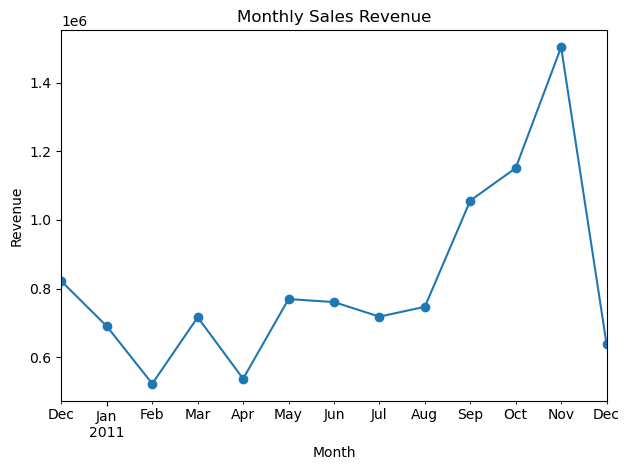

InvoiceDate
2010-12-01     821452.730
2011-01-01     689811.610
2011-02-01     522545.560
2011-03-01     716215.260
2011-04-01     536968.491
2011-05-01     769296.610
2011-06-01     760547.010
2011-07-01     718076.121
2011-08-01     746779.320
2011-09-01    1056435.192
2011-10-01    1151263.730
2011-11-01    1503866.780
2011-12-01     637790.330
Freq: MS, Name: TotalPrice, dtype: float64

In [21]:
monthly_revenue.plot(kind="line", marker="o")
plt.title("Monthly Sales Revenue")
plt.xlabel("Month")
plt.ylabel("Revenue")
plt.tight_layout()
plt.show()

monthly_revenue

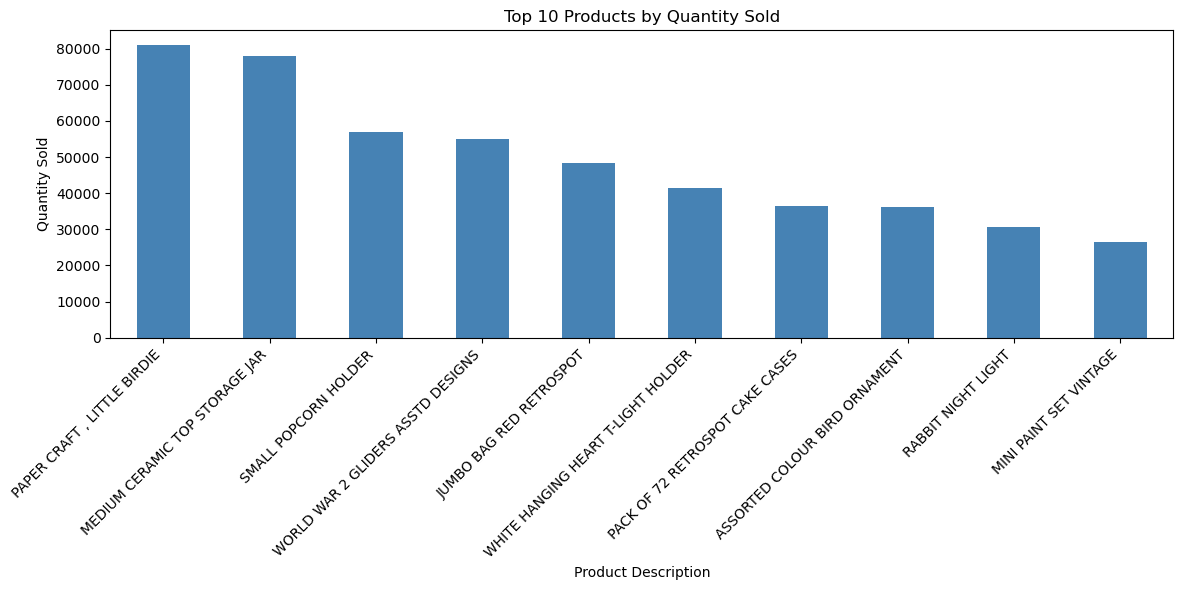

,QuantitySold,Revenue,Description
StockCode,,,
23843,80995,168469.60,"PAPER CRAFT , LITTLE BIRDIE"
23166,78033,81700.92,MEDIUM CERAMIC TOP STORAGE JAR
22197,56898,51334.47,SMALL POPCORN HOLDER
84077,54951,13814.01,WORLD WAR 2 GLIDERS ASSTD DESIGNS
85099B,48375,94159.81,JUMBO BAG RED RETROSPOT
85123A,41389,104462.75,WHITE HANGING HEART T-LIGHT HOLDER
21212,36396,21246.45,PACK OF 72 RETROSPOT CAKE CASES
84879,36202,58927.62,ASSORTED COLOUR BIRD ORNAMENT
23084,30705,66870.03,RABBIT NIGHT LIGHT


In [22]:
top_products = (
    dfsales.groupby("StockCode")
    .agg(
        QuantitySold=("Quantity", "sum"),
        Revenue=("TotalPrice", "sum"),
        Description=("Description", "first")
    )
    .sort_values("QuantitySold", ascending=False)
    .head(10)
)

plt.figure(figsize=(12, 6))

top_products["QuantitySold"].plot(
    kind="bar",
    color="steelblue"
)

plt.title("Top 10 Products by Quantity Sold")
plt.xlabel("Product Description")
plt.ylabel("Quantity Sold")

plt.xticks(
    range(len(top_products)),
    top_products["Description"],
    rotation=45,
    ha="right"
)

plt.tight_layout()
plt.show()

top_products

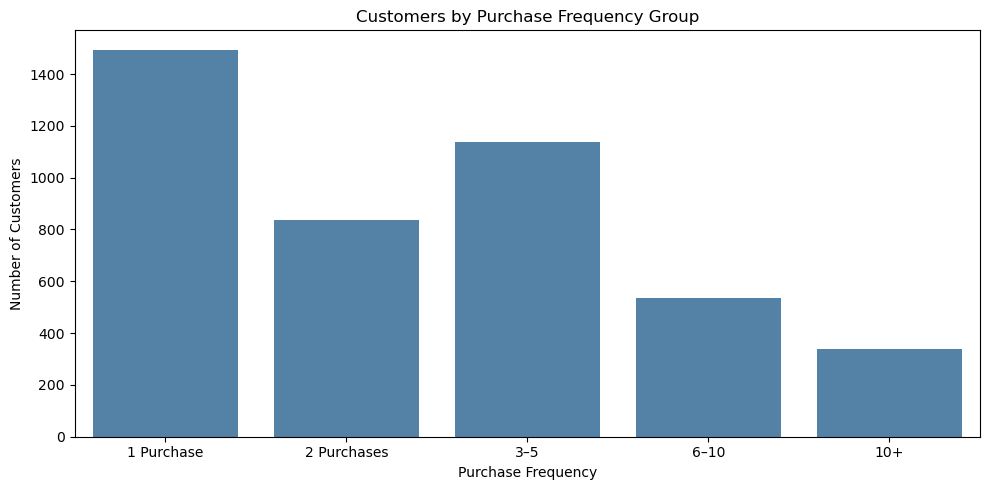

In [33]:
purchase_frequency = (
    dfsales.dropna(subset=["CustomerID"])
    .groupby("CustomerID")["InvoiceNo"]
    .nunique()
)
purchase_frequency

frequency_groups = pd.cut(
    purchase_frequency,
    bins=[0, 1, 2, 5, 10, float("inf")],
    labels=["1 Purchase", "2 Purchases", "3–5", "6–10", "10+"]
)

frequency_counts = frequency_groups.value_counts().sort_index()

plt.figure(figsize=(10, 5))

sns.barplot(
    x=frequency_counts.index,
    y=frequency_counts.values,
    color="steelblue"
)

plt.title("Customers by Purchase Frequency Group")
plt.xlabel("Purchase Frequency")
plt.ylabel("Number of Customers")

plt.tight_layout()
plt.show()


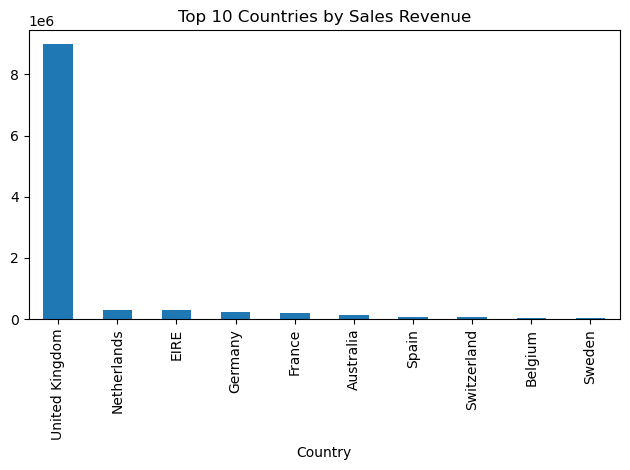

In [24]:
country_revenue = (
    dfsales.groupby("Country")["TotalPrice"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

country_revenue.plot(kind="bar")
plt.title("Top 10 Countries by Sales Revenue")
plt.tight_layout()
plt.show()

In [37]:
customer_sales = dfsales.dropna(subset=["CustomerID"]).copy()

reference_date = (customer_sales["InvoiceDate"].max() + pd.Timedelta(days=1))

rfm = customer_sales.groupby("CustomerID").agg(
    Recency=("InvoiceDate",
             lambda x: (reference_date - x.max()).days),
    Frequency=("InvoiceNo", "nunique"),
    Monetary=("TotalPrice", "sum")
).reset_index()

print(rfm.head())

   CustomerID  Recency  Frequency  Monetary
0     12346.0      326          1  77183.60
1     12347.0        2          7   4310.00
2     12348.0       75          4   1797.24
3     12349.0       19          1   1757.55
4     12350.0      310          1    334.40


In [26]:
features = ["Recency", "Frequency", "Monetary"]

scaler = StandardScaler()
X_scaled = scaler.fit_transform(rfm[features])

model = KMeans(n_clusters=4, random_state=42, n_init=10)
rfm["Cluster"] = model.fit_predict(X_scaled)

print(rfm.groupby("Cluster")[features].mean().round(2))

         Recency  Frequency   Monetary
Cluster                               
0          15.67      22.05   12435.09
1         248.56       1.55     476.33
2           7.38      82.69  127187.96
3          43.91       3.66    1344.28


C:\Users\mayan\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py:136: UserWarning: Could not find the number of physical cores for the following reason:
[WinError 2] The system cannot find the file specified
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  warnings.warn(
  File "C:\Users\mayan\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
        "wmic CPU Get NumberOfCores /Format:csv".split(),
        capture_output=True,
        text=True,
    )
  File "C:\Users\mayan\anaconda3\Lib\subprocess.py", line 554, in run
    with Popen(*popenargs, **kwargs) as process:
         ~~~~~^^^^^^^^^^^^^^^^^^^^^^
  File "C:\Users\mayan\anaconda3\Lib\subprocess.py", line 1039, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
    ~~~~~~~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^

In [27]:
rfm["R_Score"] = pd.qcut(rfm["Recency"].rank(method="first"), 5, labels=[5, 4, 3, 2, 1]).astype(int)
rfm["F_Score"] = pd.qcut(rfm["Frequency"].rank(method="first"), 5, labels=[1, 2, 3, 4, 5]).astype(int)
rfm["M_Score"] = pd.qcut(rfm["Monetary"].rank(method="first"), 5, labels=[1, 2, 3, 4, 5]).astype(int)
rfm["RFM_Score"] = ( rfm["R_Score"].astype(str) + rfm["F_Score"].astype(str) + rfm["M_Score"].astype(str))
print(rfm[["Recency", "Frequency", "Monetary","R_Score", "F_Score", "M_Score", "RFM_Score"]].head(10))

   Recency  Frequency  Monetary  R_Score  F_Score  M_Score RFM_Score
0      326          1  77183.60        1        1        5       115
1        2          7   4310.00        5        5        5       555
2       75          4   1797.24        2        4        4       244
3       19          1   1757.55        4        1        4       414
4      310          1    334.40        1        1        2       112
5       36          8   2506.04        3        5        5       355
6      204          1     89.00        1        1        1       111
7      232          1   1079.40        1        1        4       114
8      214          1    459.40        1        1        2       112
9       23          3   2811.43        4        3        5       435


In [28]:
def segment_customer(row):
    if row["R_Score"] >= 4 and row["F_Score"] >= 4:
        return "Loyal"
    elif row["M_Score"] >= 4:
        return "High-Value"
    elif row["R_Score"] <= 2:
        return "Inactive"
    else:
        return "Occasional"

rfm["Segment"] = rfm.apply(segment_customer, axis=1)
print(rfm[["Recency", "Frequency", "Monetary","RFM_Score", "Segment"]].head(10))
print("\nCustomer Segment Counts:")
count=rfm["Segment"].value_counts()
print(count)

   Recency  Frequency  Monetary RFM_Score     Segment
0      326          1  77183.60       115  High-Value
1        2          7   4310.00       555       Loyal
2       75          4   1797.24       244  High-Value
3       19          1   1757.55       414  High-Value
4      310          1    334.40       112    Inactive
5       36          8   2506.04       355  High-Value
6      204          1     89.00       111    Inactive
7      232          1   1079.40       114  High-Value
8      214          1    459.40       112    Inactive
9       23          3   2811.43       435  High-Value

Customer Segment Counts:
Segment
Inactive      1390
Loyal         1121
Occasional    1035
High-Value     793
Name: count, dtype: int64


Text(0, 0.5, 'Number of Customers')

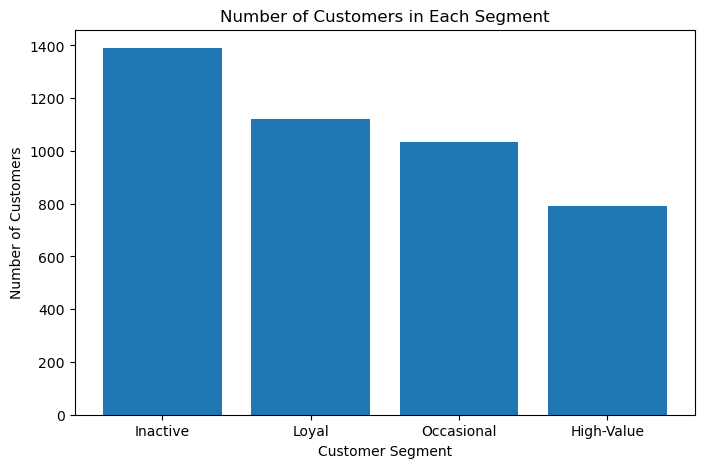

In [29]:
plt.figure(figsize=(8, 5))
plt.bar(count.index, count.values)

plt.title("Number of Customers in Each Segment")
plt.xlabel("Customer Segment")
plt.ylabel("Number of Customers")

In [38]:
split_date = customer_sales["InvoiceDate"].min() + (customer_sales["InvoiceDate"].max() - customer_sales["InvoiceDate"].min()) * 0.8

df_train = customer_sales[customer_sales["InvoiceDate"] < split_date].copy()
df_test = customer_sales[customer_sales["InvoiceDate"] >= split_date].copy()

print(f"Training period: {df_train['InvoiceDate'].min()} to {df_train['InvoiceDate'].max()}")
print(f"Test period: {df_test['InvoiceDate'].min()} to {df_test['InvoiceDate'].max()}")
print(f"Training rows: {len(df_train):,}, Test rows: {len(df_test):,}")

Training period: 2010-12-01 08:26:00 to 2011-09-25 16:06:00
Test period: 2011-09-26 07:35:00 to 2011-12-09 12:50:00
Training rows: 255,074, Test rows: 137,658


In [43]:
future_customers = customer_sales[(customer_sales["InvoiceDate"] >= split_date) & (customer_sales["InvoiceDate"] < split_date + timedelta(days= 30))]["CustomerID"].unique()

print(f"Customers who repurchased in next 30 days: {len(future_customers)}")

Customers who repurchased in next 30 days: 1374


In [46]:
rfm_train = df_train.groupby("CustomerID").agg({
    "InvoiceDate": lambda x: (split_date - x.max()).days,
    "InvoiceNo": "nunique",
    "TotalPrice": "sum"
})

rfm_train.columns = ["Recency", "Frequency", "Monetary"]
rfm_train["Target"] = rfm_train.index.isin(future_customers).astype(int)

print("Target distribution:")
print(rfm_train["Target"].value_counts())
print(f"Repurchase rate: {rfm_train['Target'].mean()*100:.2f}%")

Target distribution:
Target
0    2534
1    1016
Name: count, dtype: int64
Repurchase rate: 28.62%


In [49]:
X = rfm_train[["Recency", "Frequency", "Monetary"]].copy()
y = rfm_train["Target"].copy()

# Train-validation split
X_train, X_val, y_train, y_val = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

# Scale features for Logistic Regression
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_val_scaled = scaler.transform(X_val)

print(f"Training set: {len(X_train)}, Validation set: {len(X_val)}")
print(f"Training target distribution:\n{y_train.value_counts()}")

Training set: 2840, Validation set: 710
Training target distribution:
Target
0    2027
1     813
Name: count, dtype: int64


In [50]:
# Model 1: Logistic Regression
lr_model = LogisticRegression(random_state=42, max_iter=1000)
lr_model.fit(X_train_scaled, y_train)
y_pred_lr = lr_model.predict(X_val_scaled)
y_pred_proba_lr = lr_model.predict_proba(X_val_scaled)[:, 1]

print("LOGISTIC REGRESSION")
print(classification_report(y_val, y_pred_lr, target_names=["No Repurchase", "Repurchase"], zero_division=0))

LOGISTIC REGRESSION
               precision    recall  f1-score   support

No Repurchase       0.76      0.96      0.85       507
   Repurchase       0.72      0.24      0.36       203

     accuracy                           0.75       710
    macro avg       0.74      0.60      0.60       710
 weighted avg       0.75      0.75      0.71       710



In [51]:
# Model 2: Random Forest
rf_model = RandomForestClassifier(n_estimators=100, random_state=42, max_depth=10)
rf_model.fit(X_train, y_train)
y_pred_rf = rf_model.predict(X_val)
y_pred_proba_rf = rf_model.predict_proba(X_val)[:, 1]

print("RANDOM FOREST")
print(classification_report(y_val, y_pred_rf, target_names=["No Repurchase", "Repurchase"], zero_division=0))


RANDOM FOREST
               precision    recall  f1-score   support

No Repurchase       0.76      0.96      0.85       507
   Repurchase       0.70      0.25      0.37       203

     accuracy                           0.75       710
    macro avg       0.73      0.60      0.61       710
 weighted avg       0.74      0.75      0.71       710



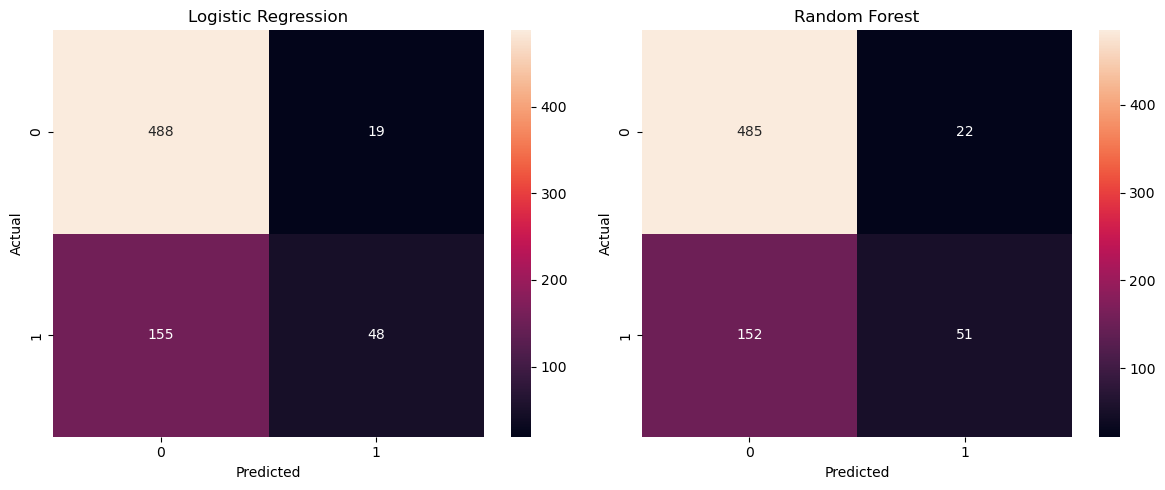

In [53]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

sns.heatmap(
    confusion_matrix(y_val, y_pred_lr),
    annot=True,
    fmt="d",
    ax=axes[0]
)
axes[0].set_title("Logistic Regression")
axes[0].set_xlabel("Predicted")
axes[0].set_ylabel("Actual")

# Random Forest confusion matrix
sns.heatmap(
    confusion_matrix(y_val, y_pred_rf),
    annot=True,
    fmt="d",
    ax=axes[1]
)
axes[1].set_title("Random Forest")
axes[1].set_xlabel("Predicted")
axes[1].set_ylabel("Actual")

plt.tight_layout()
plt.show()